In [2]:
# Import packages.
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import matplotlib.image as mpimg 
import statsmodels.api as sm
import statsmodels.formula.api as smf
import folium
from folium.plugins import HeatMap

# Read in the post-HMM data.
df_raw = pd.read_csv("joined_glm.csv")

# Show data.
df_raw

,ID,Serial,Latitude,Longitude,Pasture_Version,Position_Time,geometry,x,y,x_prev,...,speed,angle,hour,month,assigned_state,behaviour_state,NVC,grid_id,o_Ac,hab_av_o_Ac
0,294366,294366,52.641881,1.263956,3,2024-02-09 01:44:42+00:00,POINT (620925.6345823851 309905.42065747455),620925.634582,309905.420657,620912.319245,...,1.421769,1.081542,1,2,2,Intensive Foraging,W25,20085.0,0.000105,0.008913
1,294366,294366,52.641956,1.264106,3,2024-02-09 01:59:42+00:00,POINT (620935.3824034322 309914.2077924469),620935.382403,309914.207792,620925.634582,...,0.874919,-0.162877,1,2,2,Intensive Foraging,Woodland,20286.0,0.000211,0.140542
2,294366,294366,52.642029,1.262591,3,2024-02-09 05:44:42+00:00,POINT (620832.554637795 309917.7483525003),620832.554638,309917.748353,620882.837445,...,3.854310,2.339386,5,2,2,Intensive Foraging,MG1d,18187.0,0.000329,0.187990
3,294366,294366,52.642024,1.263189,3,2024-02-09 05:59:42+00:00,POINT (620872.999821663 309919.0238702598),620872.999822,309919.023870,620832.554638,...,2.697686,2.660905,5,2,3,Extensive Foraging,MG1d,19087.0,0.000276,0.187990
4,294366,294366,52.641072,1.261183,3,2024-02-09 07:14:42+00:00,POINT (620742.0878059523 309806.989144764),620742.087806,309806.989145,620814.016419,...,5.039728,-1.497036,7,2,4,Transit,MG8a,16365.0,0.000118,0.157446
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76093,295830,295830,52.639687,1.256270,72,2025-05-31 18:59:57+00:00,POINT (620416.7499079874 309637.9299272133),620416.749908,309637.929927,620460.244834,...,2.899674,-2.832395,18,5,3,Extensive Foraging,Scrub,9831.0,0.000013,0.055414
76094,295830,295830,52.639889,1.258620,72,2025-05-31 19:29:57+00:00,POINT (620574.7210257829 309667.6378053158),620574.721026,309667.637805,620352.886826,...,14.852681,-2.870669,19,5,4,Transit,MG5,13037.0,0.000026,0.063905
76095,295830,295830,52.640524,1.258008,72,2025-05-31 20:14:57+00:00,POINT (620530.1243580246 309736.359590904),620530.124358,309736.359591,620344.518146,...,13.030450,-2.656060,20,5,3,Extensive Foraging,MG8a,12151.0,0.000105,0.157446
76096,295830,295830,52.640089,1.258677,72,2025-05-31 20:30:00+00:00,POINT (620577.5785092041 309690.01739337214),620577.578509,309690.017393,620530.124358,...,4.407222,-1.082082,20,5,4,Transit,S5a,13042.0,0.000066,0.133525


In [2]:
# Folium interactive heatmap.
geo_data = df_raw[['Latitude', 'Longitude', 'Position_Time']].dropna()

heat_data = geo_data[['Latitude', 'Longitude']].values.tolist()

map_center = [geo_data['Latitude'].mean(), geo_data['Longitude'].mean()]
m = folium.Map(location=map_center, zoom_start=16)

HeatMap(heat_data, radius=1.5, blur=0.3, max_zoom=1).add_to(m)

m

In [3]:
# Calculate time allocations for behaviour states by NVC community.
profile = ( 
    df_raw.groupby(["NVC", "behaviour_state"])
    .size() 
    .groupby(level=0) 
    .apply(lambda x: 100 * x / x.sum()) 
) 

# Remove the names from the multi-index to prevent name clashing.
profile.index.names = [None] * len(profile.index.names)

# Reset the index now the names are removed.
df_clean1 = profile.reset_index(name="Allocation")

# Overwrite the column names based on their positions.
df_clean1.columns = ['Serial', 'Extra_Serial', 'behaviour_state', 'Allocation']

# Drop the duplicate column.
df_clean1 = df_clean1.drop(columns=['Extra_Serial'])

df_clean1

,Serial,behaviour_state,Allocation
0,Bankside veg,Extensive Foraging,16.528926
1,Bankside veg,Intensive Foraging,54.545455
2,Bankside veg,Resting,14.876033
3,Bankside veg,Transit,14.049587
4,Bridge,Intensive Foraging,75.000000
...,...,...,...
119,Woodland,Transit,10.173637
120,pond basin,Extensive Foraging,22.727273
121,pond basin,Intensive Foraging,50.000000
122,pond basin,Resting,4.545455


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

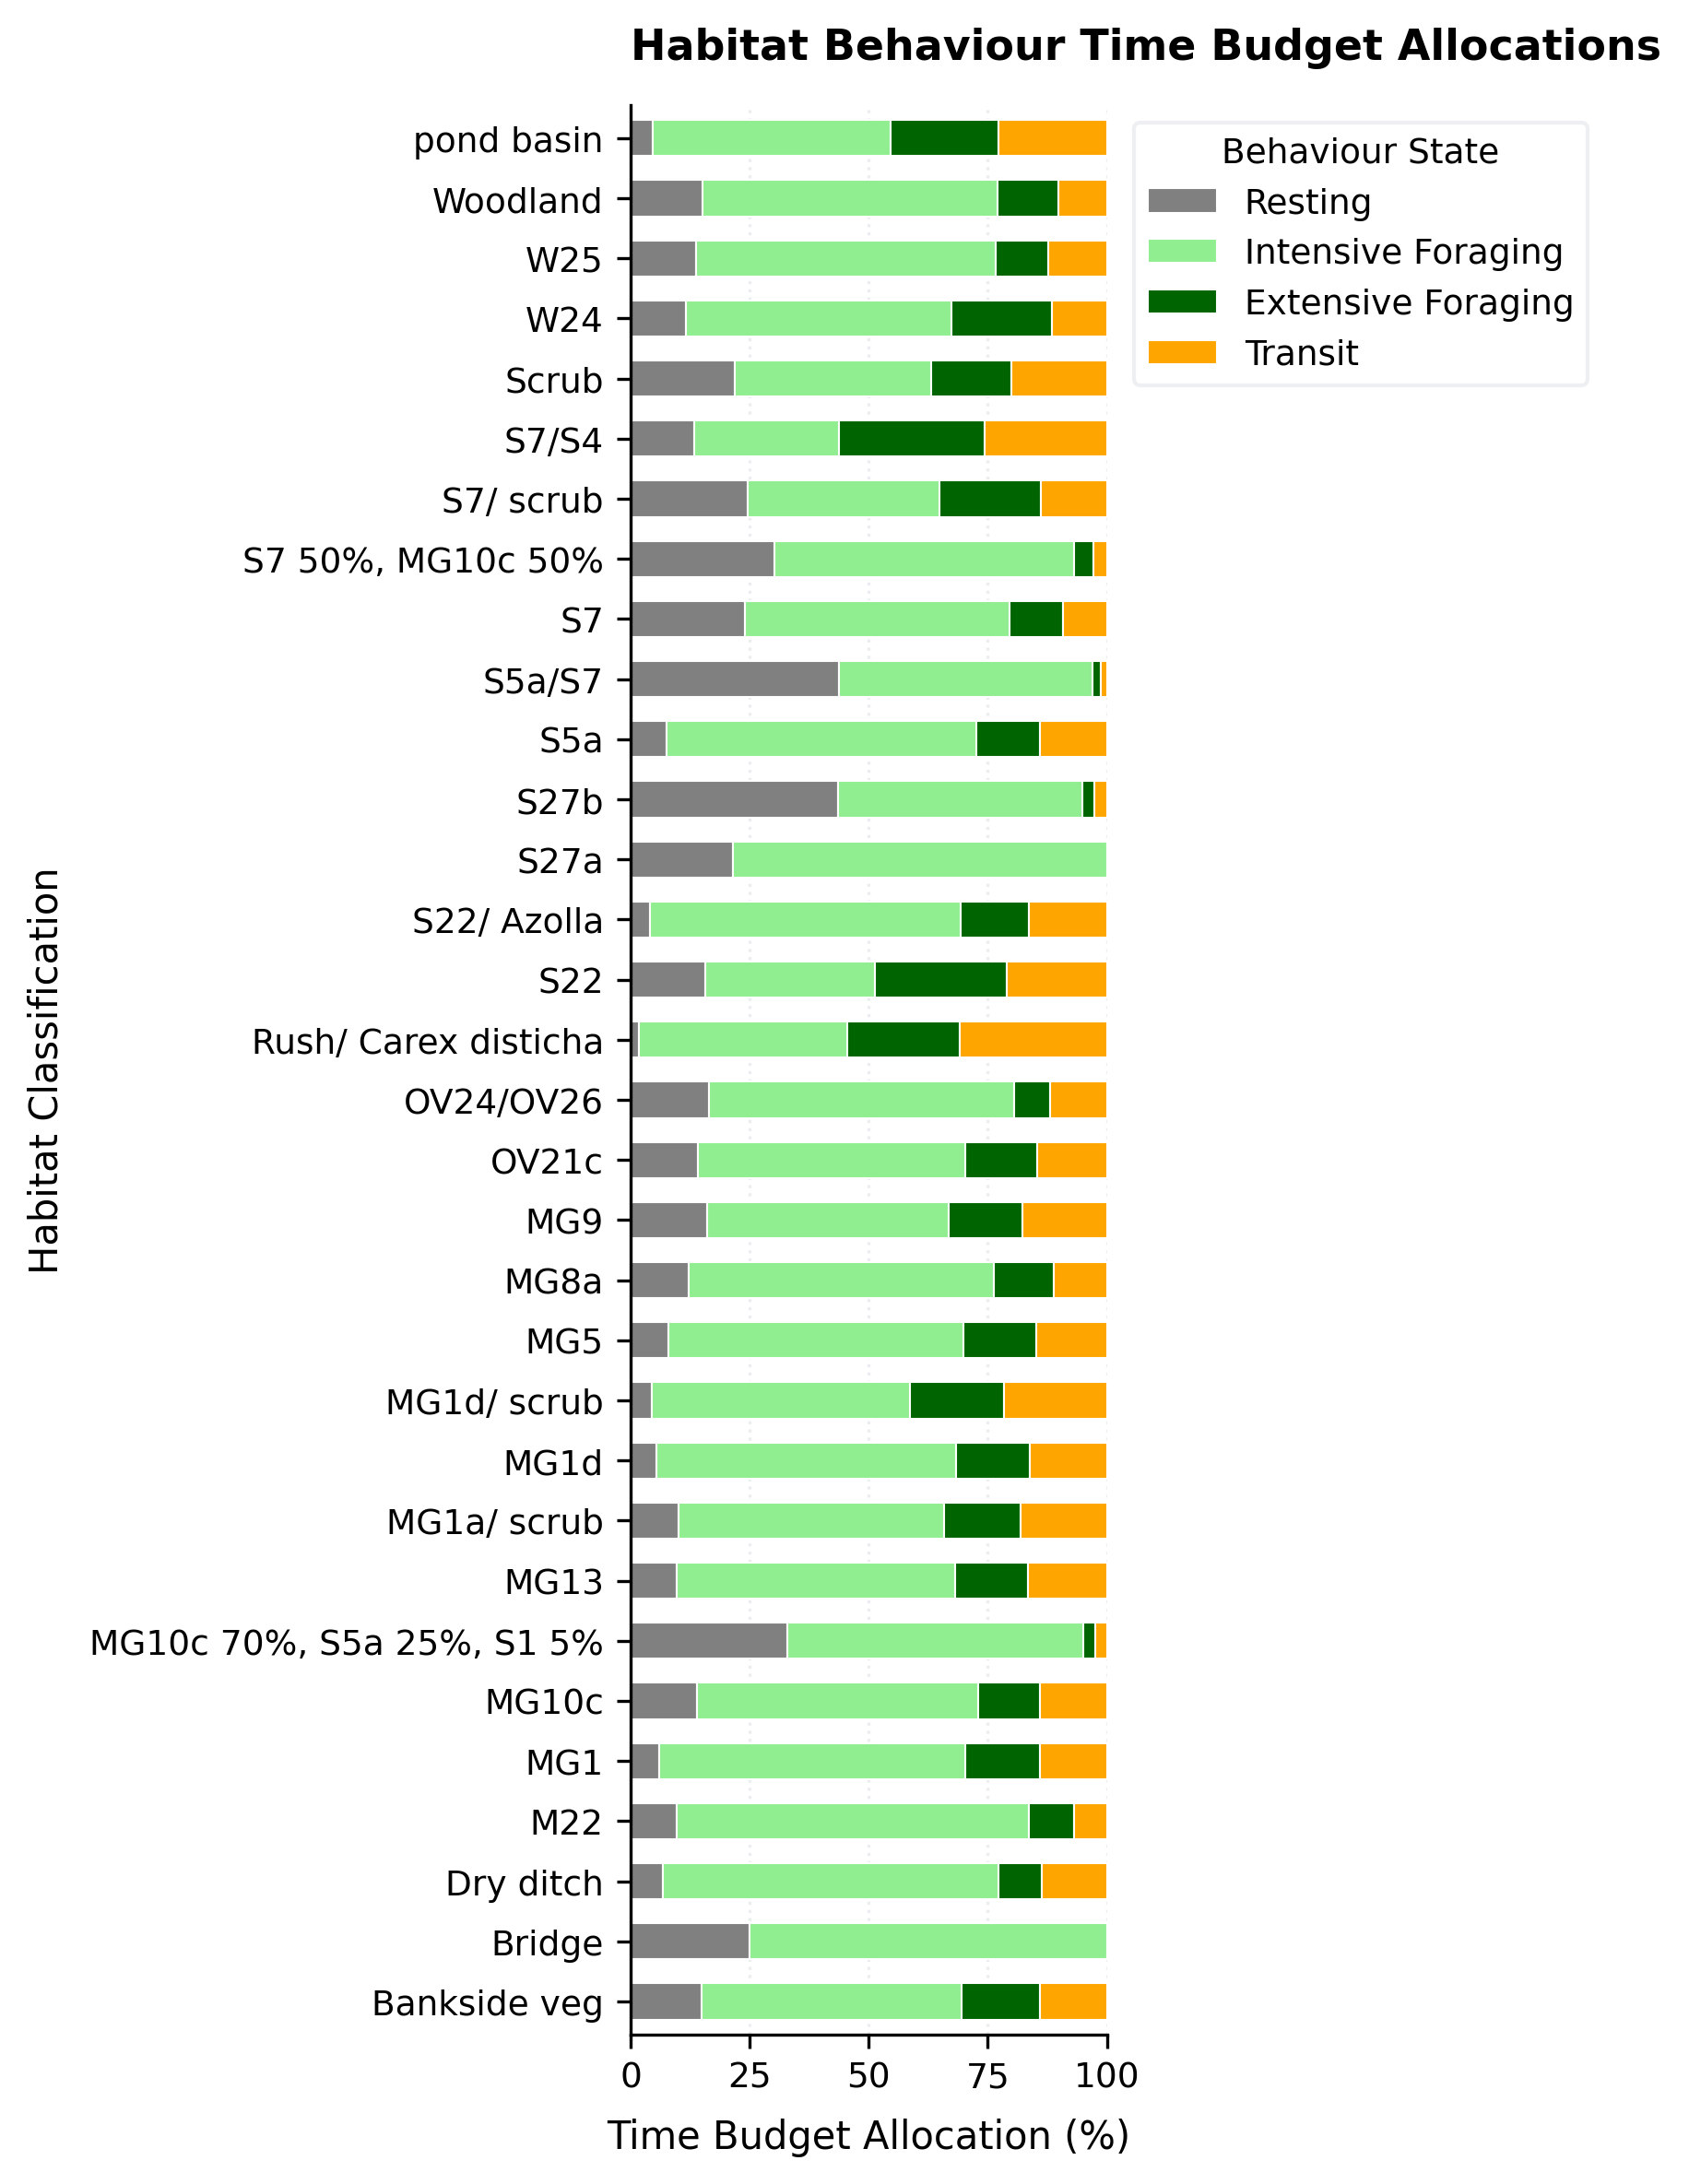

In [4]:
# Behaviour time allocation figure.
# Set global publication typography
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.linewidth'] = 0.8

# Pivot data and enforce a logical behavioral sequence
state_order = ["Resting", "Intensive Foraging", "Extensive Foraging", "Transit"]
df_pivot = df_clean1.pivot(index="Serial", columns="behaviour_state", values="Allocation")[state_order]

# Map behavioral colours.
custom_colors = {
    "Resting": "grey",            
    "Intensive Foraging": "lightgreen",   
    "Extensive Foraging": "darkgreen",   
    "Transit": "orange"                          
}

# Initialise figure canvas.
fig, ax = plt.subplots(figsize=(6, 8), dpi=300)

# Plot horizontal stacked bars.
df_pivot.plot(
    kind="barh", stacked=True, ax=ax, width=0.6,
    color=[custom_colors[s] for s in state_order],
    edgecolor="white", linewidth=0.5
)

# Editorial formatting and axis cleanup
ax.set_title("Habitat Behaviour Time Budget Allocations", fontsize=11, fontweight="bold", pad=12, loc="left")
ax.set_ylabel("Habitat Classification", fontsize=10, labelpad=6)
ax.set_xlabel("Time Budget Allocation (%)", fontsize=10, labelpad=6)

ax.set_xlim(0, 100)  # Enforce strict percentage boundary limit
ax.set_yticklabels(df_pivot.index, fontsize=8)  
ax.tick_params(labelsize=9)

# Clean background grid lines (on the x-axis to track percentage segments)
ax.grid(axis='x', linestyle=':', alpha=0.4, color='#ced4da', zorder=0)
ax.set_axisbelow(True)

# Remove heavy top and right frame outlines (Minimalist despine)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

# 8. Position the legend box cleanly on the right hand side
ax.legend(
    loc="upper left", bbox_to_anchor=(1.02, 1.0),
    frameon=True, facecolor="white", edgecolor="#e9ecef", fontsize=9,
    title="Behaviour State", title_fontsize=9
)

plt.tight_layout()

# FIRST: Save the figure with a tight bounding box to prevent legend clipping
plt.savefig('habitat_budgets_b.png', dpi=300, bbox_inches='tight')

# SECOND: Show the figure on your screen
plt.show()

In [6]:
# Load predicive model and spatial metric results data.
gpipff = pd.read_csv("gpipff4.csv")

# Calculate mean for expected daily grazing count and PFF for risk quadrant boundaries.
continuous1 = ["Exp_p_day", "PFF"] # Assigns variables to an object.

#Calculates descriptive statistics for numeric variables.
numeric1 = gpipff[continuous1].describe()
print(numeric1)

       Exp_p_day        PFF
count  32.000000  32.000000
mean    4.330000   0.061293
std     0.429437   0.113248
min     3.319000   0.000000
25%     4.120250   0.000000
50%     4.454000   0.004945
75%     4.664500   0.047575
max     5.002000   0.455000


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'sans-serif' not found because none of the following famil

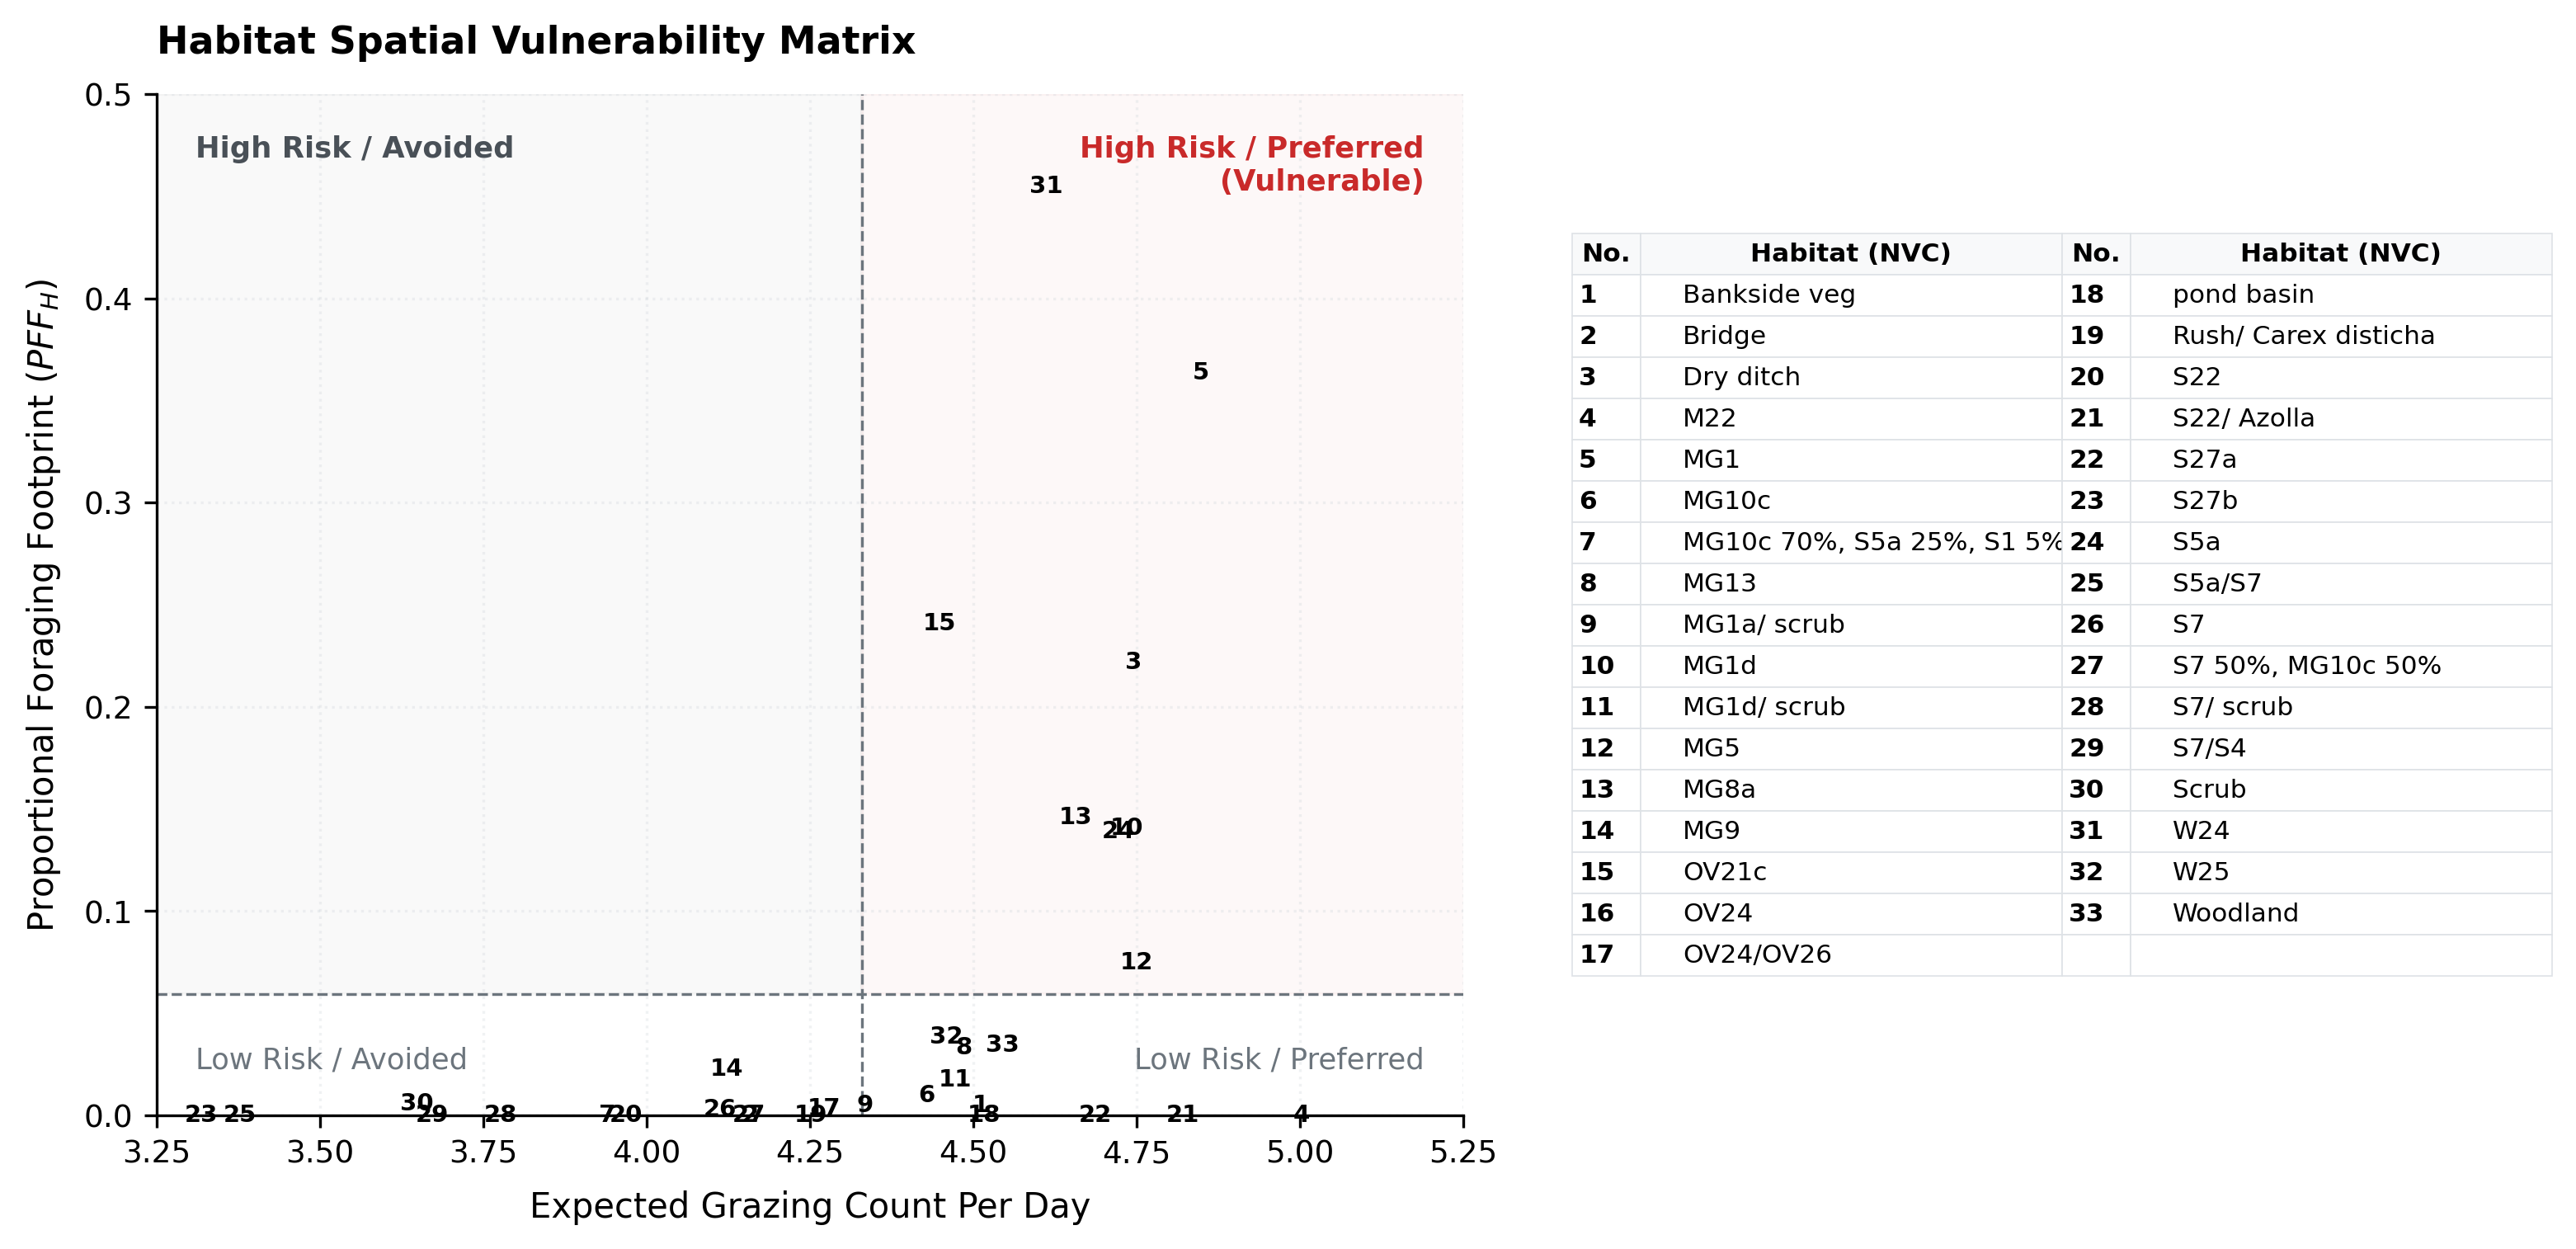

In [7]:
# Try importing adjustText to auto-resolve label overlaps. 
try:
    from adjustText import adjust_text
except ImportError:
    adjust_text = None

# 1. Set strict publication typography and styling
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['pdf.fonttype'] = 42  # Exports editable vector text for journals
plt.rcParams['ps.fonttype'] = 42

# Create figure matching double-column layout specifications
fig = plt.figure(figsize=(11, 5.5), dpi=300)

# Mock data initialization (Assumes gpipff is defined elsewhere in your environment)
habitat_summary = {
    'Habitat': gpipff["NVC"],
    'Expected Grazing Count Per Day': gpipff["Exp_p_day"],
    'PFF': gpipff["PFF"]
}
df_plot = pd.DataFrame(habitat_summary)

# Create the numeric IDs right after DataFrame initialization
df_plot['Habitat_ID'] = range(1, len(df_plot) + 1)

# Position the main plot axis explicitly to prevent collisions with the table
# format: [left, bottom, width, height]
ax = fig.add_axes([0.08, 0.12, 0.48, 0.75])

# 2. Draw quadrant background zones based on calculated thresholds
# Uses an ultra-subtle alpha (0.03) to ensure text readability
threshold_x =  4.330000
threshold_y = 0.059435

ax.axvspan(0.0, threshold_x, 0.11887, 1.0, color='#495057', alpha=0.03, zorder=0)  # Top Left
ax.axvspan(threshold_x, 12, 0.11887, 1.0, color='#c92a2a', alpha=0.03, zorder=0)  # Top Right

# 3. Draw threshold lines
ax.axvline(x=threshold_x, color='#6c757d', linestyle='--', linewidth=0.8, zorder=1)
ax.axhline(y=threshold_y, color='#6c757d', linestyle='--', linewidth=0.8, zorder=1)

# 4. Plot data points
sns.scatterplot(
    data=df_plot, x='Expected Grazing Count Per Day', y='PFF', 
    s=0, color='#005a9c', edgecolor='white', linewidth=0.6, zorder=4, ax=ax
)

# 5. Dynamic Quadrant Text (Aligned to axes fractions)
ax.text(0.03, 0.96, 'High Risk / Avoided', transform=ax.transAxes, 
        fontsize=8.5, color='#495057', fontweight='bold', va='top')
ax.text(0.97, 0.96, 'High Risk / Preferred\n(Vulnerable)', transform=ax.transAxes, 
        fontsize=8.5, color='#c92a2a', fontweight='bold', va='top', ha='right')
ax.text(0.03, 0.04, 'Low Risk / Avoided', transform=ax.transAxes, 
        fontsize=8.5, color='#6c757d', va='bottom')
ax.text(0.97, 0.04, 'Low Risk / Preferred', transform=ax.transAxes, 
        fontsize=8.5, color='#6c757d', va='bottom', ha='right')

# 6. Numeric labels and optimized adjust_text placement
texts = []
for i, row in df_plot.iterrows():
    t = ax.text(row['Expected Grazing Count Per Day'], row['PFF'], str(row['Habitat_ID']), 
                fontsize=7, fontweight='bold', va='center', ha='center', zorder=5)
    texts.append(t)

if adjust_text:
    adjust_text(
        texts, 
        arrowprops=dict(arrowstyle="-", color="#adb5bd", linewidth=0.5),
        force_points=(0.2, 0.4), 
        expand_points=(1.3, 1.3),
        ax=ax
    )

# 7. Axes limits and clean grid
ax.set_xlim(3.25, 5.25)
ax.set_ylim(0.0, 0.5)
ax.grid(True, linestyle=':', alpha=0.3, color='#ced4da', zorder=2)

# 8. Editorial labels and cleanup
ax.set_xlabel('Expected Grazing Count Per Day', fontsize=10, labelpad=6)
ax.set_ylabel('Proportional Foraging Footprint ($PFF_H$)', fontsize=10, labelpad=6)
ax.set_title('Habitat Spatial Vulnerability Matrix', fontsize=11, fontweight='bold', pad=12, loc='left')

# 9. Split and render the 33 items into a clean 2-column Legend Table
legend_data = list(zip(df_plot['Habitat_ID'], df_plot['Habitat']))
midpoint = (len(legend_data) + 1) // 2
col1_data = legend_data[:midpoint]
col2_data = legend_data[midpoint:]

table_rows = []
for i in range(midpoint):
    id1, name1 = col1_data[i]
    id2, name2 = col2_data[i] if i < len(col2_data) else ("", "")
    table_rows.append([id1, name1, id2, name2])

# Place table to the right side of the main plot area
table_ax = fig.add_axes([0.60, 0.12, 0.36, 0.75]) 
table_ax.axis('off')

matrix_table = table_ax.table(
    cellText=table_rows,
    colLabels=['No.', 'Habitat (NVC)', 'No.', 'Habitat (NVC)'],
    colWidths=[0.07, 0.43, 0.07, 0.43],
    loc='center',
    cellLoc='left'
)

# Apply publication-level font scaling and remove harsh interior lines
matrix_table.auto_set_font_size(False)
matrix_table.set_fontsize(7.5)
for (row_idx, col_idx), cell in matrix_table.get_celld().items():
    cell.set_linewidth(0.4)
    cell.set_edgecolor('#dee2e6')
    # Bold headers and index columns
    if row_idx == 0:
        cell.set_text_props(fontweight='bold')
        cell.set_facecolor('#f8f9fa')
    elif col_idx == 0 or col_idx == 2:
        cell.set_text_props(fontweight='bold')

sns.despine(ax=ax, trim=True) 

# Save outputs (Both high-res raster and infinite-resolution vector formats)
plt.savefig('Figure_2_Vulnerability_Matrix.png', bbox_inches='tight', dpi=300)
plt.savefig('Figure_2_Vulnerability_Matrix.pdf', bbox_inches='tight')
plt.show()